# UCI Steel — grafici a diverse aggregazioni temporali
Acciaieria (Corea, 2018), 15 minuti, feature ricche.

Grafici a 15 min, orario, giornaliero, settimanale, mensile + profili tipici.

> Risoluzione nativa 15 minuti: non esistono aggregazioni piu fini.

In [1]:
%matplotlib inline
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_ROOT = Path(r".")   # modifica qui se serve
UCI_PATH = DATA_ROOT / "UCI Steel" / "Steel_industry_data 2.csv"
assert UCI_PATH.exists(), f"File non trovato: {UCI_PATH}"

In [ ]:
# --- Taglio del tratto iniziale non rappresentativo (definito qui: usato al caricamento) ---
def taglia_da_operativo(s, min_fermo_giorni=30, entro_frazione=0.5, soglia=0.05, verbose=True):
    """Rimuove SOLO il lungo fermo INIZIALE (>= min_fermo_giorni) se termina entro 'entro_frazione'
    della durata: la serie riparte dalla prima operativita stabile. Adattiva per utente:
    se non c'e' un lungo fermo iniziale, restituisce la serie invariata."""
    d = s.resample("D").sum()
    med = d[d > 0].median()
    if not med or med != med: return s
    idle = (d < soglia * med)
    grp = (idle != idle.shift()).cumsum()
    tot = (d.index.max() - d.index.min()).days
    limite = d.index.min() + pd.Timedelta(days=int(tot * entro_frazione))
    fine_taglio = None
    for _, g in d.groupby(grp):
        if idle.loc[g.index].iloc[0] and len(g) >= min_fermo_giorni and g.index.max() <= limite:
            fine_taglio = g.index.max()
    if fine_taglio is None:
        if verbose: print("taglia_da_operativo: nessun lungo fermo iniziale, serie invariata.")
        return s
    start = fine_taglio + pd.Timedelta(days=1)
    if verbose:
        print(f"taglia_da_operativo: rimosso fino al {fine_taglio.date()} "
              f"(~{(start - s.index.min()).days} giorni). Serie dal {start.date()}.")
    return s.loc[start:]


In [2]:
df = pd.read_csv(UCI_PATH)
df['t'] = pd.to_datetime(df['date'], dayfirst=True)
df = df.set_index('t').sort_index()
s_raw = df['Usage_kWh'].clip(lower=0)   # dataset ORIGINALE (intatto)
s = taglia_da_operativo(s_raw)          # serie USATA in tutto il notebook
print('righe originali:', len(s_raw), '| usate:', len(s), '| periodo:', s.index.min(), '->', s.index.max())
df.head()

righe: 35040 | periodo: 2018-01-01 00:00:00 -> 2018-12-31 23:45:00


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
t,,,,,,,,,,,
2018-01-01 00:00:00,01/01/2018 00:00,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load
2018-01-01 00:15:00,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
2018-01-01 00:30:00,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2018-01-01 00:45:00,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
2018-01-01 01:00:00,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load


In [ ]:
# controllo dati mancanti (UCI = un solo impianto, un anno)
full = pd.date_range(s_raw.index.min(), s_raw.index.max(), freq='15min')
print('timestamp mancanti:', len(full) - s_raw.index.nunique(), '| NaN:', int(s_raw.isna().sum()))

### Media vs mediana (scelta della statistica)
Confronto compatto: la **media** viene abbassata dai lunghi fermi (chiusure), la **mediana** mostra il livello tipico di funzionamento. Per questo nei grafici descrittivi usiamo la **mediana**.

In [ ]:
# Confronto rapido MEDIA vs MEDIANA (perche' nei grafici usiamo la mediana)
fig, axc = plt.subplots(1, 2, figsize=(11, 2.8))
s.groupby(s.index.hour).mean().plot(ax=axc[0], marker="o", ms=3, label="media", color="#B04A3A")
s.groupby(s.index.hour).median().plot(ax=axc[0], marker="o", ms=3, label="mediana", color="#1C7293")
axc[0].set_title("profilo orario", fontsize=10); axc[0].set_xlabel("ora"); axc[0].set_ylabel("kWh/15min"); axc[0].legend(fontsize=8); axc[0].grid(True, color="#E4E9EE")
s.groupby(s.index.dayofweek).mean().plot(ax=axc[1], marker="o", ms=3, label="media", color="#B04A3A")
s.groupby(s.index.dayofweek).median().plot(ax=axc[1], marker="o", ms=3, label="mediana", color="#1C7293")
axc[1].set_title("profilo settimanale", fontsize=10); axc[1].set_xticks(range(7)); axc[1].set_xticklabels(["Lun","Mar","Mer","Gio","Ven","Sab","Dom"]); axc[1].legend(fontsize=8); axc[1].grid(True, color="#E4E9EE")
plt.suptitle("Media vs mediana: la mediana ignora i lunghi fermi -> livello tipico (piu espressivo)", fontsize=10)
plt.tight_layout(); plt.show()


## Funzioni di utilita

In [3]:
# --- funzioni di utilita (aggregazioni + grafici) ---
FREQ = {"15 min":"15min", "Orario":"h", "Giornaliero":"D",
        "Settimanale":"W", "Mensile":"ME", "Annuale":"YE"}

# Capodanno lunare (festa mobile)
CAPODANNO_LUNARE = {2016:"2016-02-08",2017:"2017-01-28",2018:"2018-02-16",2019:"2019-02-05",
                    2020:"2020-01-25",2021:"2021-02-12",2022:"2022-02-01",2023:"2023-01-22",
                    2024:"2024-02-10",2025:"2025-01-29",2026:"2026-02-17"}
# Periodi COVID (modificabili). Default = fase acuta in Cina (lockdown Wuhan -> riapertura).
# Per una finestra piu ampia della pandemia usare es. ("2020-01-23","2022-12-31").
PERIODI_COVID = [("2020-01-23", "2020-04-08")]

def _finestre_capodanno(gp=7, gd=10):
    return [(pd.Timestamp(d)-pd.Timedelta(days=gp), pd.Timestamp(d)+pd.Timedelta(days=gd))
            for d in CAPODANNO_LUNARE.values()]

def _overlay_eventi(ax=None, festivita=True, covid=True):
    """Ombreggia Capodanno lunare (rosso) e periodo COVID (viola) senza allargare l'asse x."""
    if not (festivita or covid): return
    ax = ax or plt.gca()
    xmin, xmax = ax.get_xlim()
    if festivita:
        for a, b in _finestre_capodanno():
            ax.axvspan(a, b, color="#B04A3A", alpha=0.12, zorder=0)
    if covid:
        for a, b in PERIODI_COVID:
            ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#5B4B8A", alpha=0.15, zorder=0)
    ax.set_xlim(xmin, xmax)

def aggrega(s, rule, how="sum"):
    return getattr(s.resample(rule), how)()

def plot_serie(s, rule="D", how="sum", finestra=None, titolo=None, festivita=True, covid=True):
    x = aggrega(s, rule, how) if rule else s
    if finestra:
        x = x.loc[finestra[0]:finestra[1]]
    plt.figure(figsize=(12, 3.8))
    plt.plot(x.index, x.values, lw=0.7 if len(x) > 1500 else 1.4, color="#1C7293", zorder=3)
    _overlay_eventi(plt.gca(), festivita, covid)   # rosso=Capodanno, viola=COVID
    plt.title(titolo or f"{rule} ({how})", color="#0F2E4C")
    plt.ylabel("kWh" if how == "sum" else "kWh/step (media)")
    plt.grid(True, color="#E4E9EE"); plt.tight_layout(); plt.show()

def plot_profili(s, stat="mediana"):
    f = "median" if str(stat).startswith("median") else "mean"
    lab = "mediana" if f == "median" else "media"
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    gg = ["Lun","Mar","Mer","Gio","Ven","Sab","Dom"]
    getattr(s.groupby(s.index.hour), f)().plot(ax=ax[0], marker="o", color="#0F2E4C")
    ax[0].set_title(f"{lab} per ora"); ax[0].set_xlabel("ora")
    getattr(s.groupby(s.index.dayofweek), f)().plot(ax=ax[1], marker="o", color="#2C5F2D")
    ax[1].set_title(f"{lab} per giorno"); ax[1].set_xticks(range(7)); ax[1].set_xticklabels(gg)
    getattr(s.groupby(s.index.month), f)().plot(ax=ax[2], marker="o", color="#B04A3A")
    ax[2].set_title(f"{lab} per mese"); ax[2].set_xlabel("mese")
    for a in ax: a.grid(True, color="#E4E9EE")
    plt.tight_layout(); plt.show()

def tabella_aggregazioni(s):
    import pandas as pd
    return pd.DataFrame([(n, r, len(aggrega(s, r, "sum"))) for n, r in FREQ.items()],
                        columns=["Aggregazione", "regola", "n. punti"])


In [4]:
tabella_aggregazioni(s)

,Aggregazione,regola,n. punti
0,15 min,15min,35040
1,Orario,h,8760
2,Giornaliero,D,365
3,Settimanale,W,53
4,Mensile,ME,12
5,Annuale,YE,1


## Serie a diverse aggregazioni

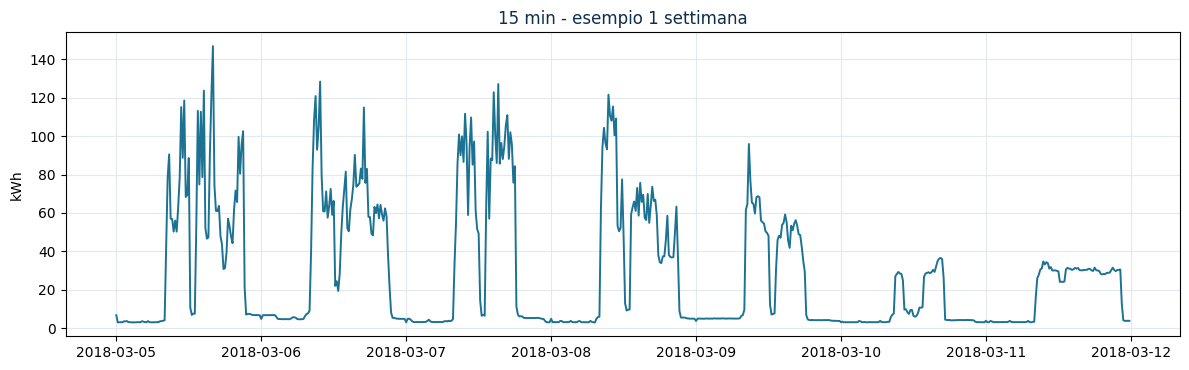

In [5]:
plot_serie(s, rule=None, finestra=('2018-03-05','2018-03-11'), titolo='15 min - esempio 1 settimana')

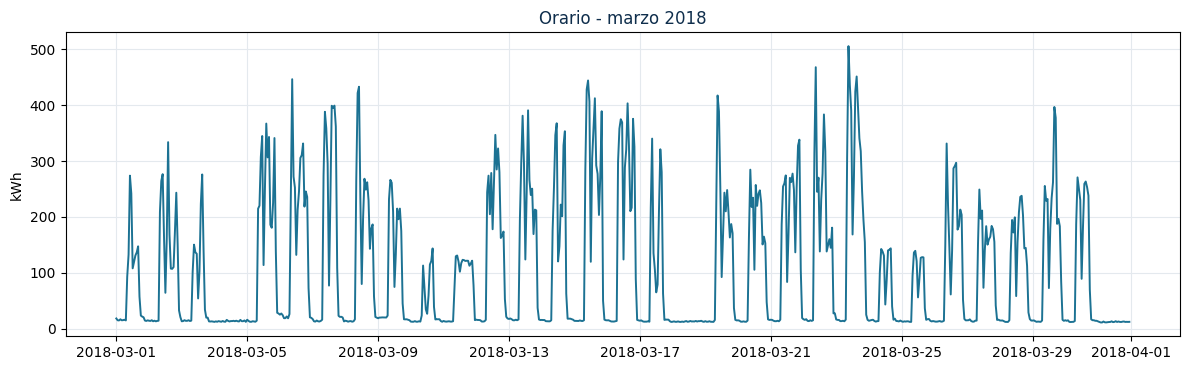

In [6]:
plot_serie(s, rule='h', how='sum', finestra=('2018-03-01','2018-03-31'), titolo='Orario - marzo 2018')

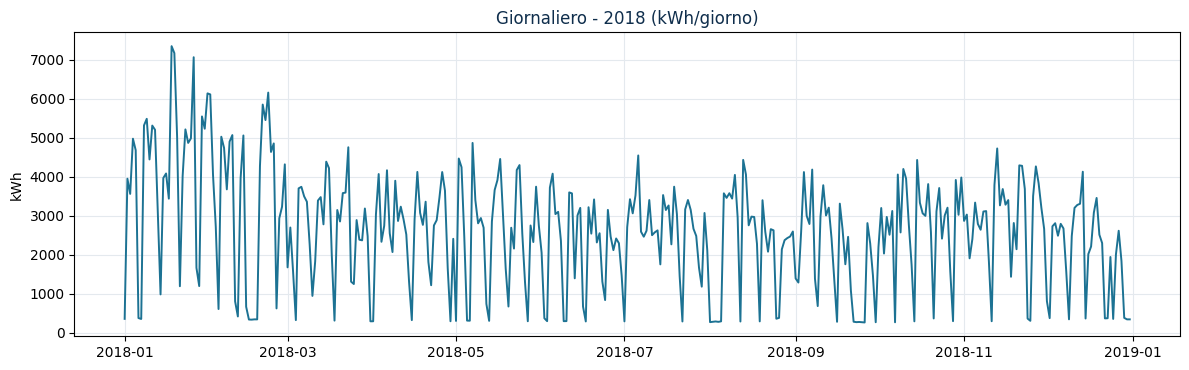

In [7]:
plot_serie(s, rule='D', how='sum', titolo='Giornaliero - 2018 (kWh/giorno)')

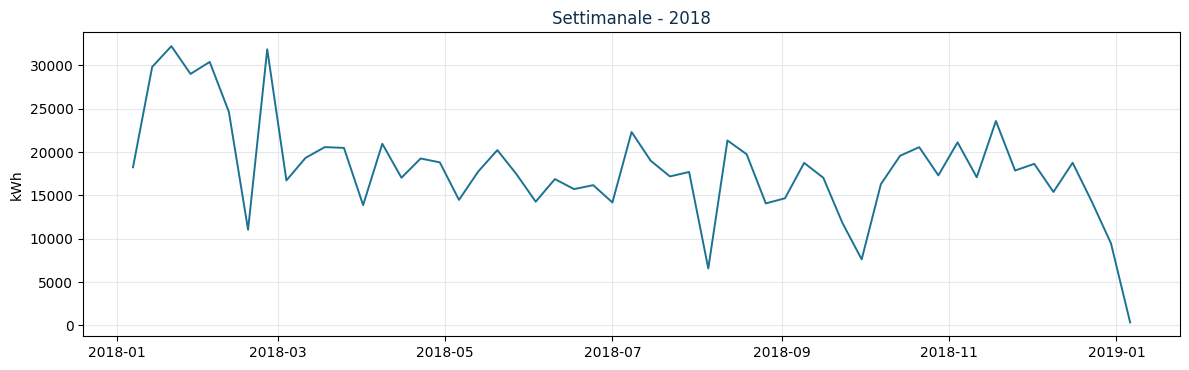

In [8]:
plot_serie(s, rule='W', how='sum', titolo='Settimanale - 2018')

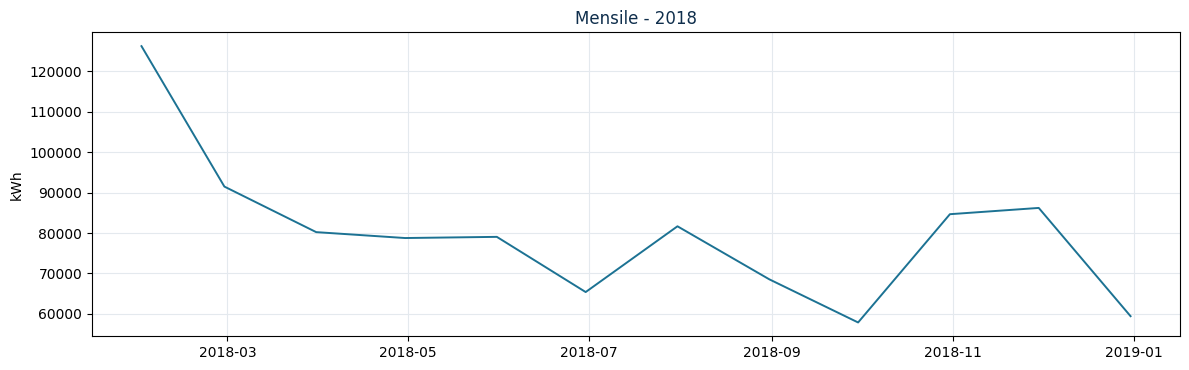

In [9]:
plot_serie(s, rule='ME', how='sum', titolo='Mensile - 2018')

## Profili tipici (medie)

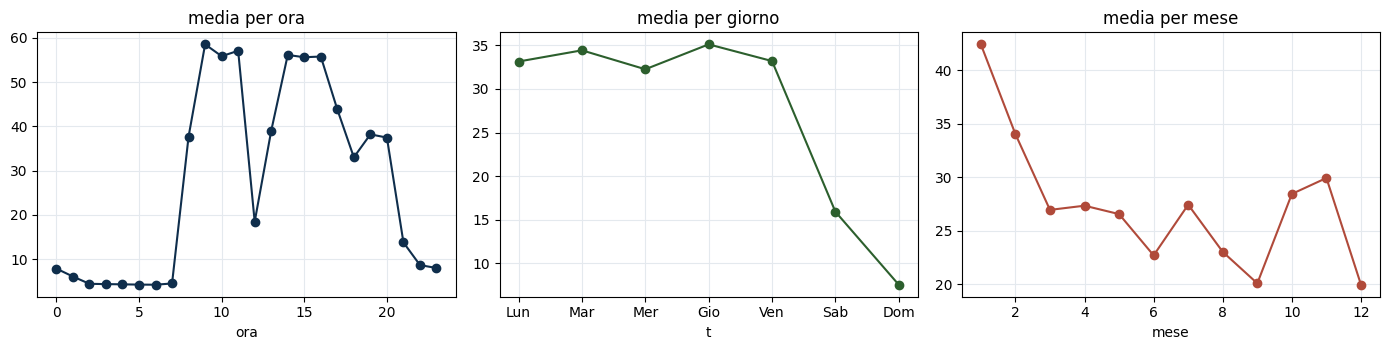

In [10]:
plot_profili(s)

## Extra — consumo medio per stato di carico (Load_Type)

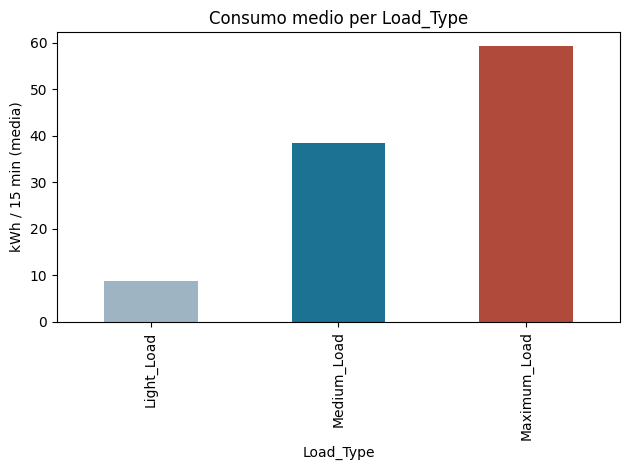

In [11]:
df.groupby('Load_Type')['Usage_kWh'].mean().reindex(['Light_Load','Medium_Load','Maximum_Load']).plot(kind='bar', color=['#9FB4C2','#1C7293','#B04A3A'])
plt.ylabel('kWh / 15 min (media)'); plt.title('Consumo medio per Load_Type'); plt.tight_layout(); plt.show()

## Heatmap
Visualizzano il consumo su due dimensioni temporali contemporaneamente.

In [12]:
# --- HEATMAP ---
def heatmap_ora_mese(s, stat="mediana", titolo=None):
    f = "median" if str(stat).startswith("median") else "mean"
    h = getattr(s.resample("h"), f)()
    piv = (pd.DataFrame({"ora": h.index.hour, "mese": h.index.month, "v": h.values})
             .pivot_table(index="ora", columns="mese", values="v", aggfunc=f))
    plt.figure(figsize=(9, 5))
    im = plt.imshow(piv.values, aspect="auto", origin="lower", cmap="viridis")
    plt.colorbar(im, label=f"kWh/ora ({'mediana' if f=='median' else 'media'})")
    plt.yticks(range(0, 24, 2)); plt.xticks(range(piv.shape[1]), piv.columns)
    plt.ylabel("ora"); plt.xlabel("mese"); plt.title(titolo or "Heatmap ora x mese")
    plt.tight_layout(); plt.show()

def heatmap_giorno_ora(s, stat="mediana", titolo=None):
    f = "median" if str(stat).startswith("median") else "mean"
    piv = (pd.DataFrame({"ora": s.index.hour, "gg": s.index.dayofweek, "v": s.values})
             .pivot_table(index="ora", columns="gg", values="v", aggfunc=f))
    plt.figure(figsize=(7, 5))
    im = plt.imshow(piv.values, aspect="auto", origin="lower", cmap="viridis")
    plt.colorbar(im, label=f"kWh/15min ({'mediana' if f=='median' else 'media'})")
    plt.yticks(range(0, 24, 2)); plt.xticks(range(7), ["Lun","Mar","Mer","Gio","Ven","Sab","Dom"])
    plt.ylabel("ora"); plt.title(titolo or "Heatmap giorno x ora")
    plt.tight_layout(); plt.show()

def heatmap_calendario(s, how="sum", titolo=None, festivita=True, covid=True):
    """Righe = ora, colonne = date. Linee rosse = Capodanno lunare; banda viola = COVID."""
    h = getattr(s.resample("h"), how)()
    piv = (pd.DataFrame({"giorno": h.index.normalize(), "ora": h.index.hour, "v": h.values})
             .pivot_table(index="ora", columns="giorno", values="v"))
    giorni = list(piv.columns)
    def _ip(dt):
        return min(range(len(giorni)), key=lambda i: abs((giorni[i]-dt).days))
    plt.figure(figsize=(13, 4))
    im = plt.imshow(piv.values, aspect="auto", origin="lower", cmap="viridis")
    plt.colorbar(im, label="kWh/ora")
    pos = [i for i, d in enumerate(giorni) if d.day == 1]
    if len(pos) > 18: pos = pos[::3]
    plt.xticks(pos, [giorni[i].strftime("%Y-%m") for i in pos], rotation=45, ha="right")
    if covid:
        for a, b in PERIODI_COVID:
            a, b = pd.Timestamp(a), pd.Timestamp(b)
            if giorni[0] <= b and a <= giorni[-1]:
                plt.axvspan(_ip(max(a, giorni[0])), _ip(min(b, giorni[-1])), color="#5B4B8A", alpha=0.20, zorder=2)
    if festivita:
        for d in CAPODANNO_LUNARE.values():
            d = pd.Timestamp(d)
            if giorni[0] <= d <= giorni[-1]:
                plt.axvline(_ip(d), color="#B04A3A", lw=1.2, ls="--", alpha=0.85)
    plt.ylabel("ora"); plt.yticks(range(0, 24, 4)); plt.xlabel("data (tempo)")
    plt.title(titolo or "Heatmap calendario — rosso=Capodanno, viola=COVID")
    plt.tight_layout(); plt.show()


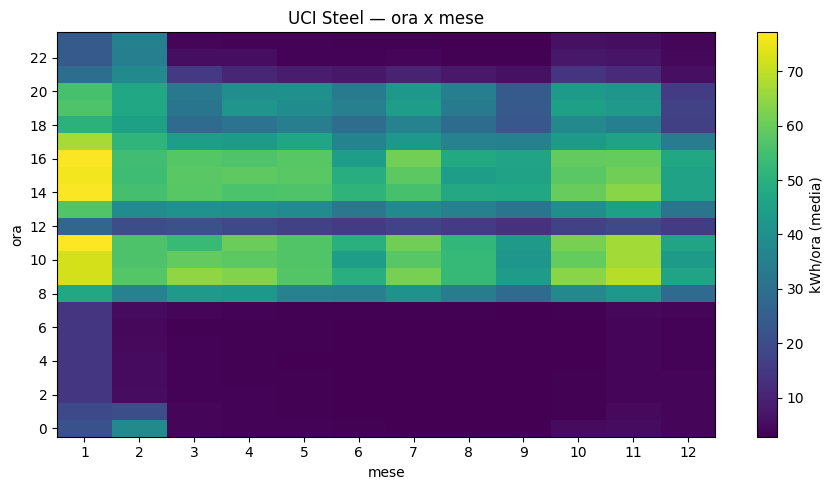

In [13]:
heatmap_ora_mese(s, titolo='UCI Steel — ora x mese')

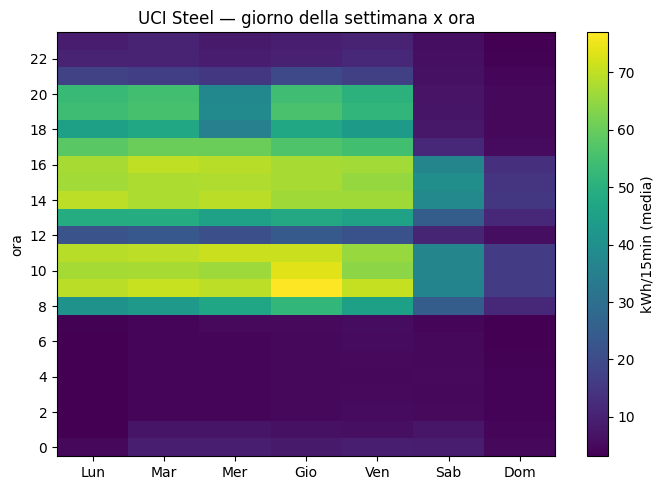

In [14]:
heatmap_giorno_ora(s, titolo='UCI Steel — giorno della settimana x ora')

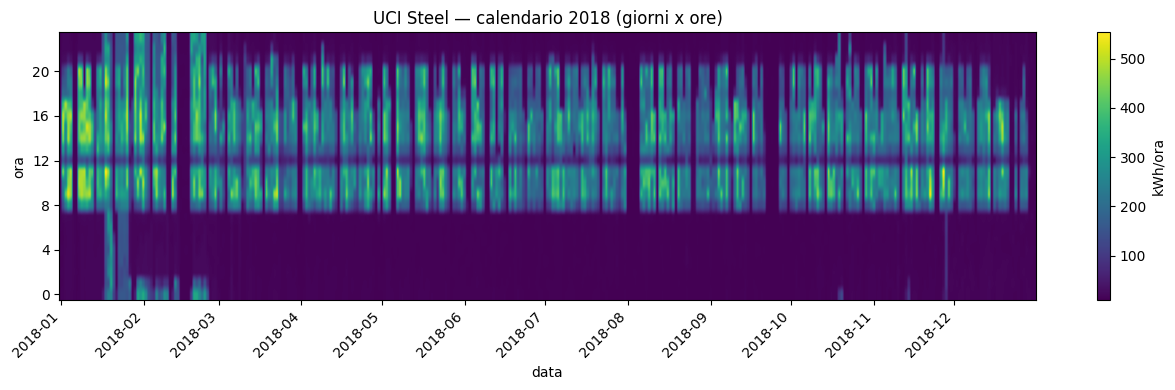

In [15]:
heatmap_calendario(s, titolo='UCI Steel — calendario 2018 (giorni x ore)')

## Boxplot
Distribuzione (mediana, quartili) del consumo per raggruppamento.

In [16]:
# --- BOXPLOT ---
def boxplot_per(s, by="ora", titolo=None):
    """Distribuzione del consumo raggruppata per ora / giorno / mese (variabilita)."""
    key = {"ora": s.index.hour, "giorno": s.index.dayofweek, "mese": s.index.month}[by]
    cats = sorted(pd.unique(key))
    data = [s.values[key == c] for c in cats]
    plt.figure(figsize=(12, 4))
    bp = plt.boxplot(data, showfliers=False, patch_artist=True)
    for b in bp["boxes"]: b.set_facecolor("#9FC0D4")
    if by == "giorno":
        plt.xticks(range(1, 8), ["Lun","Mar","Mer","Gio","Ven","Sab","Dom"])
    else:
        plt.xticks(range(1, len(cats) + 1), [str(c) for c in cats])
    plt.ylabel("kWh / 15 min"); plt.title(titolo or f"Boxplot per {by}")
    plt.grid(True, axis="y", color="#E4E9EE"); plt.tight_layout(); plt.show()


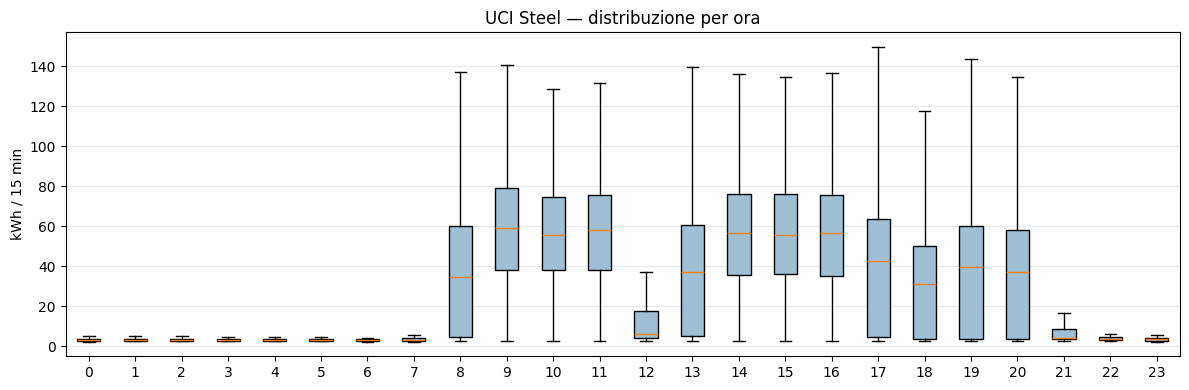

In [17]:
boxplot_per(s, by='ora', titolo='UCI Steel — distribuzione per ora')

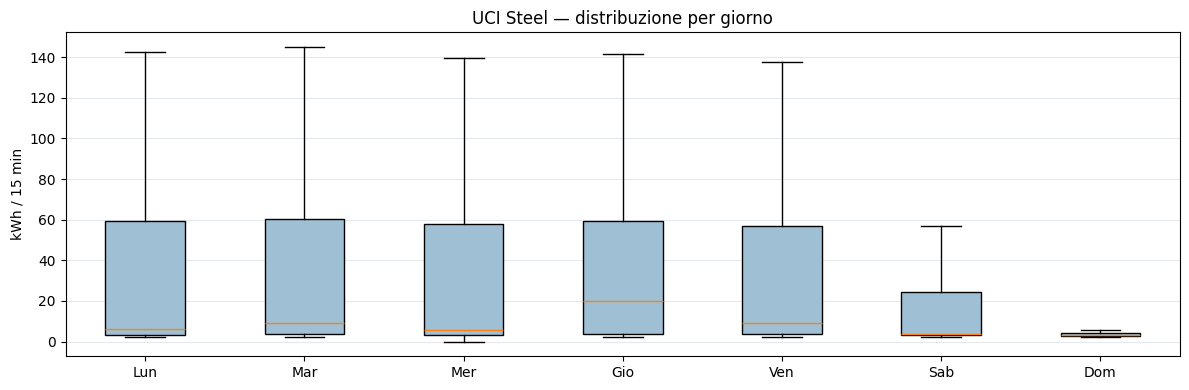

In [18]:
boxplot_per(s, by='giorno', titolo='UCI Steel — distribuzione per giorno')

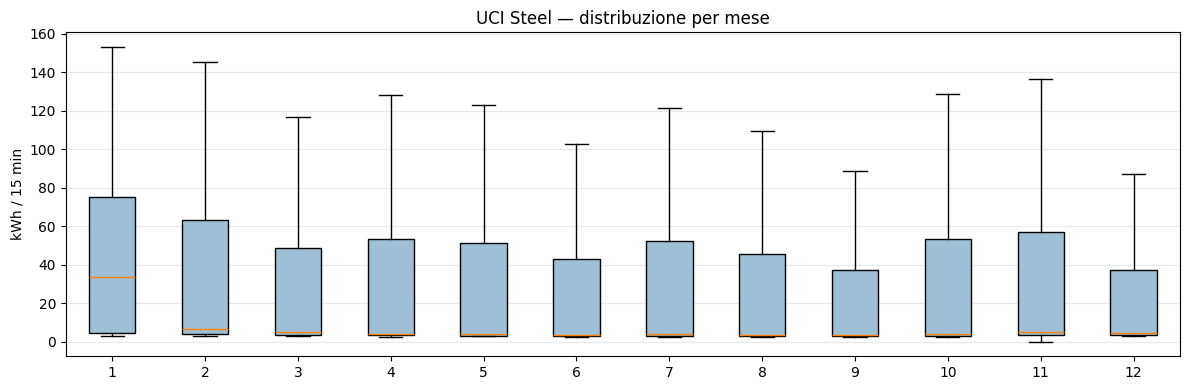

In [19]:
boxplot_per(s, by='mese', titolo='UCI Steel — distribuzione per mese')

### Boxplot per stato di carico (Load_Type)

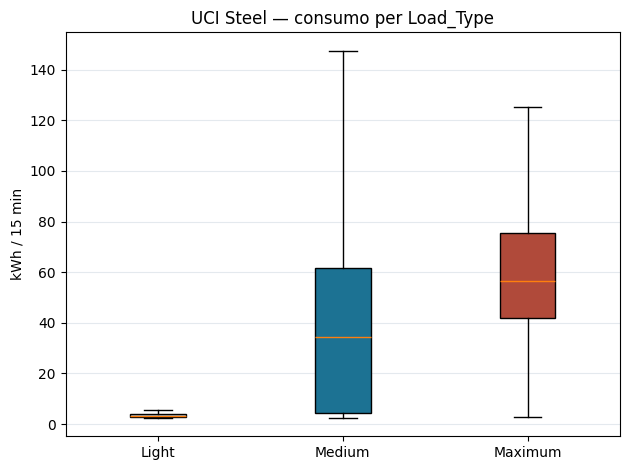

In [20]:
import numpy as np
order=['Light_Load','Medium_Load','Maximum_Load']
data=[df.loc[df['Load_Type']==k,'Usage_kWh'].values for k in order]
bp=plt.boxplot(data, showfliers=False, patch_artist=True)
for b,c in zip(bp['boxes'],['#9FB4C2','#1C7293','#B04A3A']): b.set_facecolor(c)
plt.xticks([1,2,3],['Light','Medium','Maximum']); plt.ylabel('kWh / 15 min')
plt.title('UCI Steel — consumo per Load_Type'); plt.grid(True,axis='y',color='#E4E9EE'); plt.tight_layout(); plt.show()

## Heatmap di correlazione
Correlazione (Pearson) tra le variabili numeriche. Utile per capire quali grandezze si muovono insieme al consumo (es. CO2 e reattiva) e quali sono piu indipendenti.

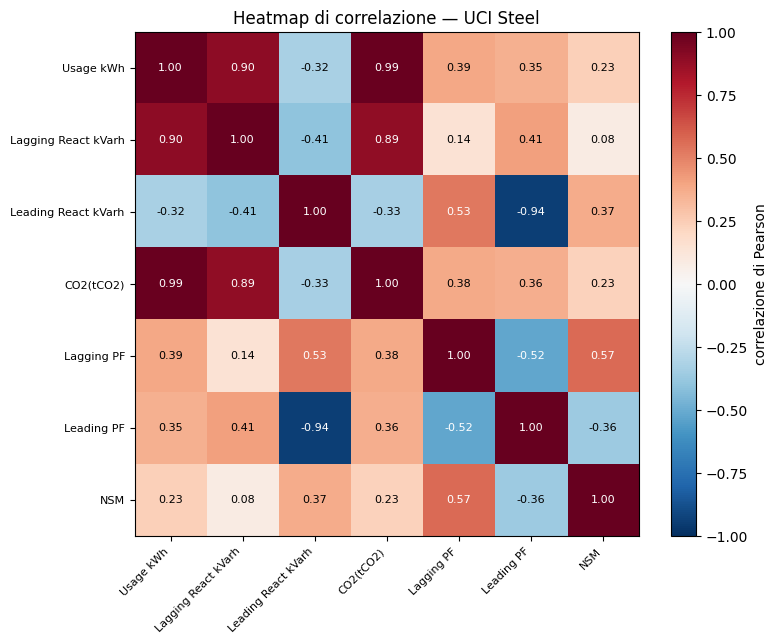

In [21]:
# --- HEATMAP DI CORRELAZIONE (solo UCI Steel: ha piu variabili numeriche) ---
num = ["Usage_kWh","Lagging_Current_Reactive.Power_kVarh","Leading_Current_Reactive_Power_kVarh",
       "CO2(tCO2)","Lagging_Current_Power_Factor","Leading_Current_Power_Factor","NSM"]
C = df[num].corr(method="pearson")   # metodo: 'pearson' (lineare) o 'spearman' (di rango)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_yticks(range(len(num)))
etich = [c.replace("_Current","").replace("Reactive.Power","React").replace("Reactive_Power","React")
          .replace("_Power_Factor"," PF").replace("_"," ")[:20] for c in num]
ax.set_xticklabels(etich, rotation=45, ha="right", fontsize=8); ax.set_yticklabels(etich, fontsize=8)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{C.values[i,j]:.2f}", ha="center", va="center",
                color="white" if abs(C.values[i,j])>0.5 else "black", fontsize=8)
fig.colorbar(im, label="correlazione di Pearson"); ax.set_title("Heatmap di correlazione — UCI Steel")
plt.tight_layout(); plt.show()


## Trend e stagionalita
Per il **trend** usiamo le medie mobili (sotto). Per la **stagionalita** usiamo la decomposizione **MSTL** (sezione piu avanti), che estrae piu cicli insieme — piu adatta della STL a periodo singolo.

In [22]:
# --- TREND (medie mobili) ---
def evidenzia_trend(s, titolo=None, festivita=True, covid=True):
    d = s.resample("D").sum()
    plt.figure(figsize=(12, 4))
    plt.plot(d.index, d.values, color="#C7D2DB", lw=0.8, label="giornaliero", zorder=3)
    plt.plot(d.index, d.rolling(30, min_periods=7).mean(),  color="#1C7293", lw=2, label="media mobile 30g", zorder=4)
    plt.plot(d.index, d.rolling(90, min_periods=20).mean(), color="#B04A3A", lw=2, label="media mobile 90g (trend)", zorder=5)
    _overlay_eventi(plt.gca(), festivita, covid)
    plt.legend(); plt.xlabel("data"); plt.ylabel("kWh/giorno")
    plt.title(titolo or "Trend con medie mobili"); plt.grid(True, color="#E4E9EE")
    plt.tight_layout(); plt.show()


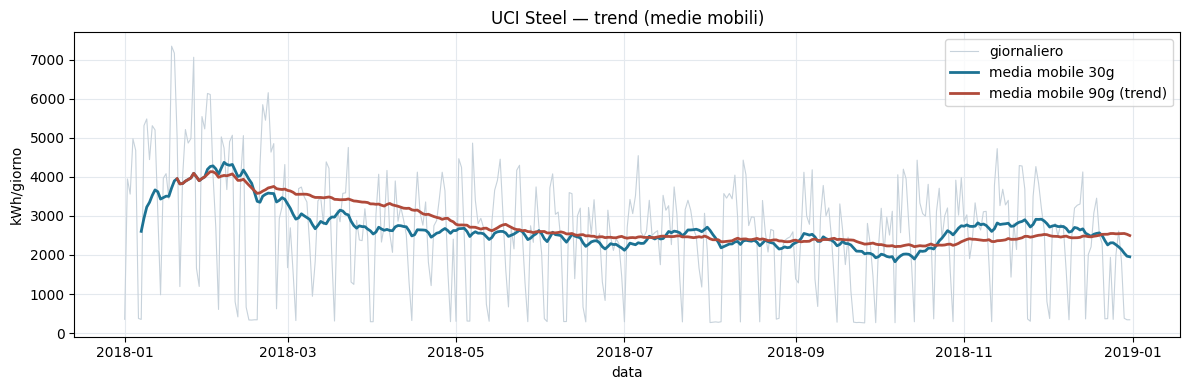

In [23]:
evidenzia_trend(s, titolo='UCI Steel — trend (medie mobili)')

## Autocorrelazione (ACF / PACF)
Misurano quanto un valore dipende dai valori passati.

- **ACF**: correlazione con i valori a distanza *lag*. Picchi regolari = **periodicita** (es. a lag 24 = ciclo giornaliero sui dati orari; a lag 168 = settimanale).
- **PACF**: correlazione 'netta' a un lag, tolti gli effetti dei lag intermedi. Serve a scegliere l'**ordine AR** di modelli tipo ARIMA.

Come leggere: barre che escono dalla banda azzurra = correlazioni statisticamente significative.

In [25]:
# --- AUTOCORRELAZIONE (ACF / PACF) ---
# richiede statsmodels
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def acf_pacf(s, agg="h", nlags=168, titolo=None):
    """ACF e PACF su una aggregazione scelta.
    ACF: correlazione della serie con se stessa a distanza 'lag' (mostra periodicita e persistenza).
    PACF: correlazione 'netta' a un dato lag (aiuta a scegliere l'ordine AR di un modello).
    Suggerimenti: agg='h', nlags=168 -> vede ciclo giornaliero (24) e settimanale (168);
                  agg='D', nlags=35  -> vede ciclo settimanale (7) sui dati giornalieri."""
    x = s.resample(agg).sum().dropna() if agg else s.dropna()
    nlags = int(min(nlags, len(x)//2 - 1))
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
    plot_acf(x, lags=nlags, ax=ax[0]); ax[0].set_title((titolo or "") + f"  ACF ({agg}, {nlags} lag)")
    plot_pacf(x, lags=nlags, ax=ax[1], method="ywm"); ax[1].set_title("PACF")
    for a in ax: a.grid(True, color="#E4E9EE")
    plt.tight_layout(); plt.show()


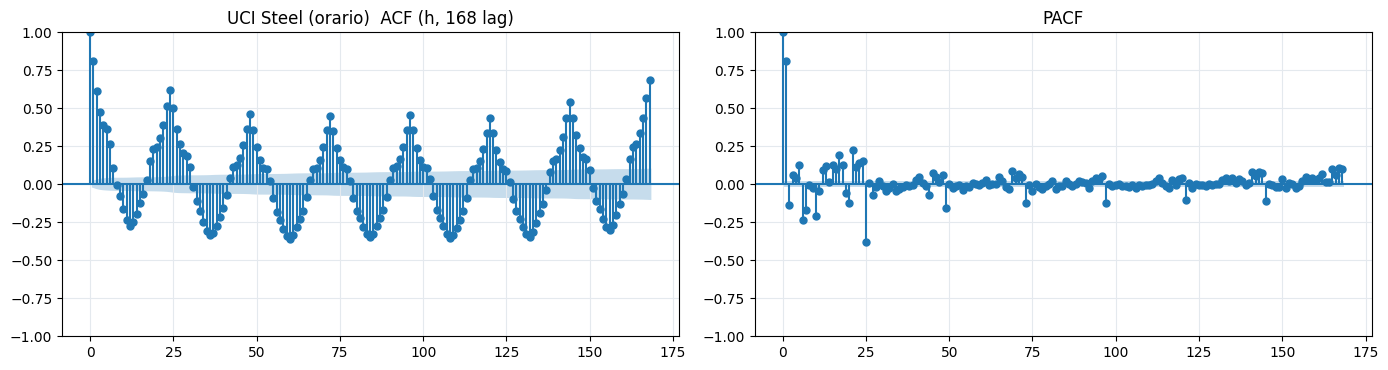

In [26]:
acf_pacf(s, agg='h', nlags=168, titolo='UCI Steel (orario)')   # ciclo giornaliero (24) e settimanale (168)

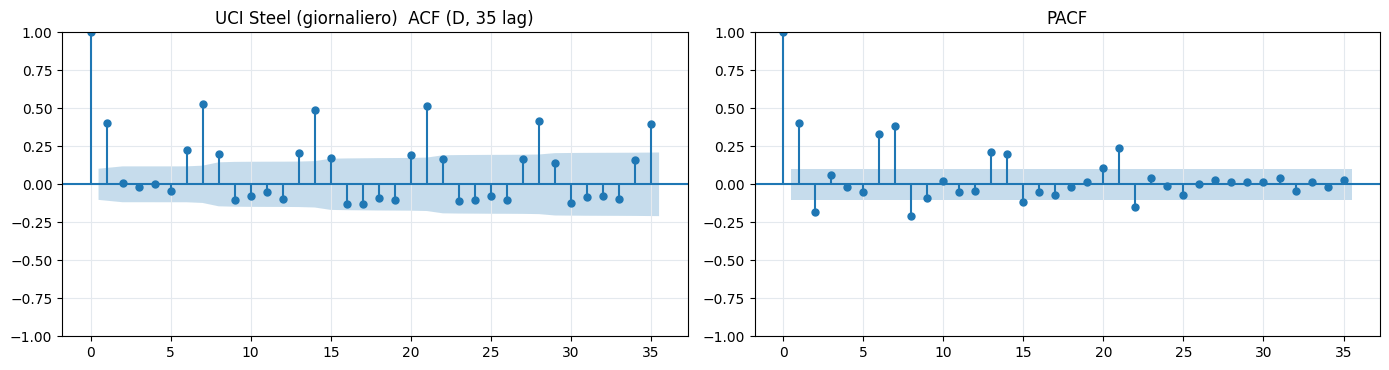

In [27]:
acf_pacf(s, agg='D', nlags=35, titolo='UCI Steel (giornaliero)')  # ciclo settimanale (7)

## Feature di calendario — Capodanno lunare e flag 'fermo'
Il Capodanno lunare (festa **mobile**: cambia data ogni anno) causa fermate dell'impianto, soprattutto in Cina (EWELD); in Corea (UCI) l'effetto e' piu lieve. **Non si eliminano** questi giorni: si **marcano** con feature apposite, cosi il modello li impara.

`crea_features(s)` restituisce un DataFrame pronto per la modellazione (consumo + ora/giorno/mese/weekend + festa_lunare + fermo).

In [ ]:
# --- FEATURE DI CALENDARIO + flag "fermo" ---
def flag_capodanno(index, giorni_prima=7, giorni_dopo=10):
    m = np.zeros(len(index), dtype=bool)
    for dt in CAPODANNO_LUNARE.values():
        dt = pd.Timestamp(dt)
        m |= (index >= dt - pd.Timedelta(days=giorni_prima)) & (index <= dt + pd.Timedelta(days=giorni_dopo))
    return pd.Series(m, index=index)

def flag_covid(index):
    m = np.zeros(len(index), dtype=bool)
    for a, b in PERIODI_COVID:
        m |= (index >= pd.Timestamp(a)) & (index <= pd.Timestamp(b))
    return pd.Series(m, index=index)

def flag_fermo(s, finestra_giorni=30, soglia=0.2):
    d = s.resample("D").sum()
    base = d.rolling(finestra_giorni, min_periods=7, center=True).median()
    return (d < soglia * base).reindex(s.index, method="ffill").fillna(False)

def crea_features(s, taglia_iniziale=False):
    """Feature per la modellazione. NB: la serie 's' e' gia' quella tagliata (vedi cella di caricamento);
    taglia_iniziale=True riapplica il taglio se parti da 's_raw'."""
    if taglia_iniziale:
        s = taglia_da_operativo(s)
    X = pd.DataFrame(index=s.index)
    X["consumo"]      = s.values
    X["ora"]          = s.index.hour
    X["giorno_sett"]  = s.index.dayofweek
    X["mese"]         = s.index.month
    X["weekend"]      = (s.index.dayofweek >= 5).astype(int)
    X["festa_lunare"] = flag_capodanno(s.index).astype(int)
    X["covid"]        = flag_covid(s.index).astype(int)
    X["fermo"]        = flag_fermo(s).astype(int)
    return X

def plot_flag(s, anno=None, titolo=None):
    """Consumo giornaliero con fermo (grigio), Capodanno (rosso), COVID (viola).
    anno=None -> sceglie automaticamente l'anno con piu dati per l'utente selezionato."""
    if anno is None:
        anno = int(pd.Series(s.index.year).value_counts().idxmax())
    d = s.resample("D").sum().loc[f"{anno}-01-01":f"{anno}-12-31"]
    fc = flag_capodanno(d.index); cv = flag_covid(d.index)
    ff = flag_fermo(s).resample("D").max().reindex(d.index).fillna(False)
    plt.figure(figsize=(13, 3.8))
    plt.plot(d.index, d.values, color="#1C7293", lw=1.2, zorder=3)
    top = d.max() if d.max() and d.max() == d.max() else 1
    plt.fill_between(d.index, 0, top, where=ff.values, color="#C7D2DB", alpha=0.6, label="fermo (inferito)")
    plt.fill_between(d.index, 0, top, where=cv.values, color="#5B4B8A", alpha=0.22, label="COVID")
    plt.fill_between(d.index, 0, top, where=fc.values, color="#B04A3A", alpha=0.25, label="Capodanno lunare")
    plt.legend(); plt.ylabel("kWh/giorno"); plt.title(titolo or f"Flag calendario — {anno} (auto)")
    plt.grid(True, color="#E4E9EE"); plt.tight_layout(); plt.show()


In [ ]:
X = crea_features(s)
X.head()

In [ ]:
plot_flag(s, anno=2019, titolo='Flag: Capodanno lunare (rosso) e fermo (grigio)')

## Decomposizione multi-stagionale
`decomponi_multi` estrae **giornaliera + settimanale + annuale** e produce un **trend lento e pulito** (non una stagionalita mascherata). L'annuale e' calcolata come profilo giorno-dell'anno ed e' inclusa solo se lo storico e' >= 2 anni.

- `agg='h'` (consigliato): giornaliera+settimanale via MSTL + annuale.
- `trend_giorni`: ampiezza del lisciamento del trend (default 30 giorni).

In [ ]:
# --- DECOMPOSIZIONE MULTI-STAGIONALE (giornaliera + settimanale + annuale, trend pulito) ---
from statsmodels.tsa.seasonal import MSTL

def decomponi_multi(s, agg="h", annuale="auto", trend_giorni=30, zoom_giorni=21, stat="mediana",
                    titolo=None, festivita=True, covid=True):
    """Giornaliera+settimanale via MSTL; ANNUALE via profilo giorno-dell'anno; TREND via lisciamento.
    stat='mediana' (default) -> annuale e trend calcolati con la MEDIANA (robusta ai fermi);
    stat='media' -> con la media."""
    f = "median" if str(stat).startswith("median") else "mean"
    passi = {"15min":96, "h":24}.get(agg, 24)
    x = s.resample(agg).sum().asfreq(agg).interpolate(limit_direction="both")
    res = MSTL(x, periods=(passi, passi*7)).fit()
    daily  = res.seasonal.iloc[:, 0]
    weekly = res.seasonal.iloc[:, 1]
    deseason = x - daily - weekly
    anni = (x.index.max() - x.index.min()).days / 365.25
    usa_ann = (annuale is True) or (annuale == "auto" and anni >= 2)
    if usa_ann:
        annual = deseason.groupby(deseason.index.dayofyear).transform(f)   # mediana/media per giorno-anno
        senza = deseason - annual
    else:
        annual = None; senza = deseason
        if annuale == "auto": print("Annuale non estratta (storico < 2 anni).")
    win = max(passi * trend_giorni, 3)
    trend = getattr(senza.rolling(win, min_periods=max(win//3, 2), center=True), f)()  # mediana/media mobile
    resid = senza - trend

    lente = [(f"trend (pulito, {stat})", trend, "#1C7293")]
    if annual is not None: lente.append((f"annuale ({stat} giorno-anno)", annual, "#2C5F2D"))
    nrow = 2 + len(lente)
    fig, ax = plt.subplots(nrow, 1, figsize=(12, 1.9*nrow), sharex=True)
    ax[0].plot(x.index, x.values, color="#243642", lw=0.7); ax[0].set_ylabel("osservato")
    for i,(nome,serie,col) in enumerate(lente):
        ax[1+i].plot(serie.index, serie.values, color=col, lw=1.6); ax[1+i].set_ylabel(nome)
    ax[-1].plot(resid.index, resid.values, color="#B04A3A", lw=0.6); ax[-1].set_ylabel("residuo"); ax[-1].set_xlabel("data (tempo)")
    for a in ax: a.grid(True, color="#E4E9EE"); _overlay_eventi(a, festivita, covid)
    fig.suptitle(titolo or f"Decomposizione multi-stagionale ({stat}) — agg='{agg}'")
    plt.tight_layout(); plt.show()

    n_g = passi * zoom_giorni
    fig2, ax2 = plt.subplots(2, 1, figsize=(12, 5))
    ax2[0].plot(daily.index[:n_g], daily.values[:n_g], color="#7FA9C9")
    ax2[0].set_title(f"stagionalita giornaliera — primi {zoom_giorni} giorni"); ax2[0].set_ylabel("giornaliera"); ax2[0].grid(True, color="#E4E9EE")
    ax2[1].plot(weekly.index[:n_g], weekly.values[:n_g], color="#5DCAA5")
    ax2[1].set_title(f"stagionalita settimanale — primi {zoom_giorni} giorni"); ax2[1].set_ylabel("settimanale"); ax2[1].set_xlabel("data"); ax2[1].grid(True, color="#E4E9EE")
    plt.tight_layout(); plt.show()

    r = resid.dropna()
    def _fz(c):
        cc = c.reindex(r.index).values
        return round(max(0.0, 1 - np.nanvar(r.values)/np.nanvar(cc + r.values)), 3)
    forze = {"giornaliera": _fz(daily), "settimanale": _fz(weekly)}
    if annual is not None: forze["annuale"] = _fz(annual)
    print("Forza stagionalita:", forze)
    return {"trend":trend, "giornaliera":daily, "settimanale":weekly, "annuale":annual, "residuo":resid, "x":x}


In [ ]:
# giornaliera + settimanale + ANNUALE, con trend pulito
res_multi = decomponi_multi(s, agg='h', titolo='Multi-stagionale (giorn.+sett.+annuale)')

## Decomposizione: cosa usare per ogni orizzonte
- **`decomponi_multi(s, agg='h')`** -> BREVE + MEDIO + LUNGO: estrae stagionalita **giornaliera + settimanale + annuale** (annuale ove possibile) e restituisce un **trend pulito**. E' la vista completa.
- **`mstl_nativo(s, agg='D')`** -> MEDIO + LUNGO: MSTL nativa con periodi **[7, 365]** (settimanale + annuale) e `res.plot()`. E' quella con il trend piu pulito che preferisci.

Rimosso il native orario [24,168]: su dati pluriennali il suo trend contiene ancora l'annuale (fuorviante).

In [ ]:
# --- MSTL NATIVA (stile documentazione statsmodels: res.plot()) ---
from statsmodels.tsa.seasonal import MSTL

def mstl_nativo(s, agg="D", periodi=None, robust=True, titolo=None):
    """Riproduce l'esempio statsmodels: MSTL(...).fit() + res.plot() + zoom sulle stagionali.
    agg='D' -> periodi [7, 365] (settimanale + annuale, se lo storico basta)."""
    x = s.resample(agg).sum().asfreq(agg).interpolate(limit_direction="both")
    if periodi is None:
        periodi = [24, 24*7] if agg == "h" else [7, 365]
    periodi = [p for p in periodi if len(x) >= 2*p]
    print("Periodi usati:", periodi)
    mstl = MSTL(x, periods=periodi, iterate=3,
                stl_kwargs={"seasonal_deg": 0, "inner_iter": 2, "outer_iter": 0, "robust": robust})
    res = mstl.fit()
    fig = res.plot()                 # grafico nativo impilato
    fig.set_size_inches(14, 10)      # ingrandisci (default troppo piccolo)
    plt.suptitle(titolo or f"MSTL nativa — periodi {periodi} (agg={agg})")
    plt.tight_layout(); plt.show()
    # zoom sulle componenti stagionali (primi 3 cicli), come nell'esempio statsmodels
    cols = list(res.seasonal.columns)
    fig, axz = plt.subplots(nrows=len(cols), figsize=(11, 3.2*len(cols)))
    if len(cols) == 1: axz = [axz]
    for i, c in enumerate(cols):
        p = int("".join(ch for ch in c if ch.isdigit()))
        res.seasonal[c].iloc[: p*3].plot(ax=axz[i], color="#2C5F2D")
        axz[i].set_ylabel(c); axz[i].set_title(f"stagionalita {c} — primi 3 cicli"); axz[i].grid(True, color="#E4E9EE")
    plt.tight_layout(); plt.show()
    return res


## Taglio del tratto iniziale non rappresentativo
Se un utente ha un **lungo fermo iniziale** (es. avvio/commissioning), `taglia_da_operativo` fa ripartire la serie dalla prima operativita stabile. E' opzionale e **per singolo utente** (gli zeri sono dati reali, non mancanti: si tolgono solo se non rappresentativi).

In [ ]:
# 's' e' gia' la serie con il taglio iniziale; 's_raw' e' l'originale intatto.
# Per disattivare il taglio per questo utente:  s = s_raw
print('originale:', len(s_raw), '| con taglio:', len(s))